<a href="https://colab.research.google.com/github/kara04y/2026_Intro_Python/blob/main/FEEDBACK_KARA_YENNY_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feedback : Exercice 1.6

In [1]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

print(states_path)

/root/.cache/mlees/us_states.geojson


In [2]:
# Q1 : Import geopandas (as gpd), pandas, and matplotlib
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Q2 : Read the data with the geopandasfunction
country = gpd.read_file(states_path)
country.head()

# Q3 : # Print out the first few lines of the data
print(country.geometry.head(5)) # It contains multipolygons and polygons


0    MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ...
1    MULTIPOLYGON (((-166.10574 53.98861, -166.0752...
2    POLYGON ((-112.53859 37.00067, -112.53454 37.0...
3    POLYGON ((-94.04296 33.01922, -94.04304 33.079...
4    MULTIPOLYGON (((-122.42144 37.86997, -122.4213...
Name: geometry, dtype: geometry


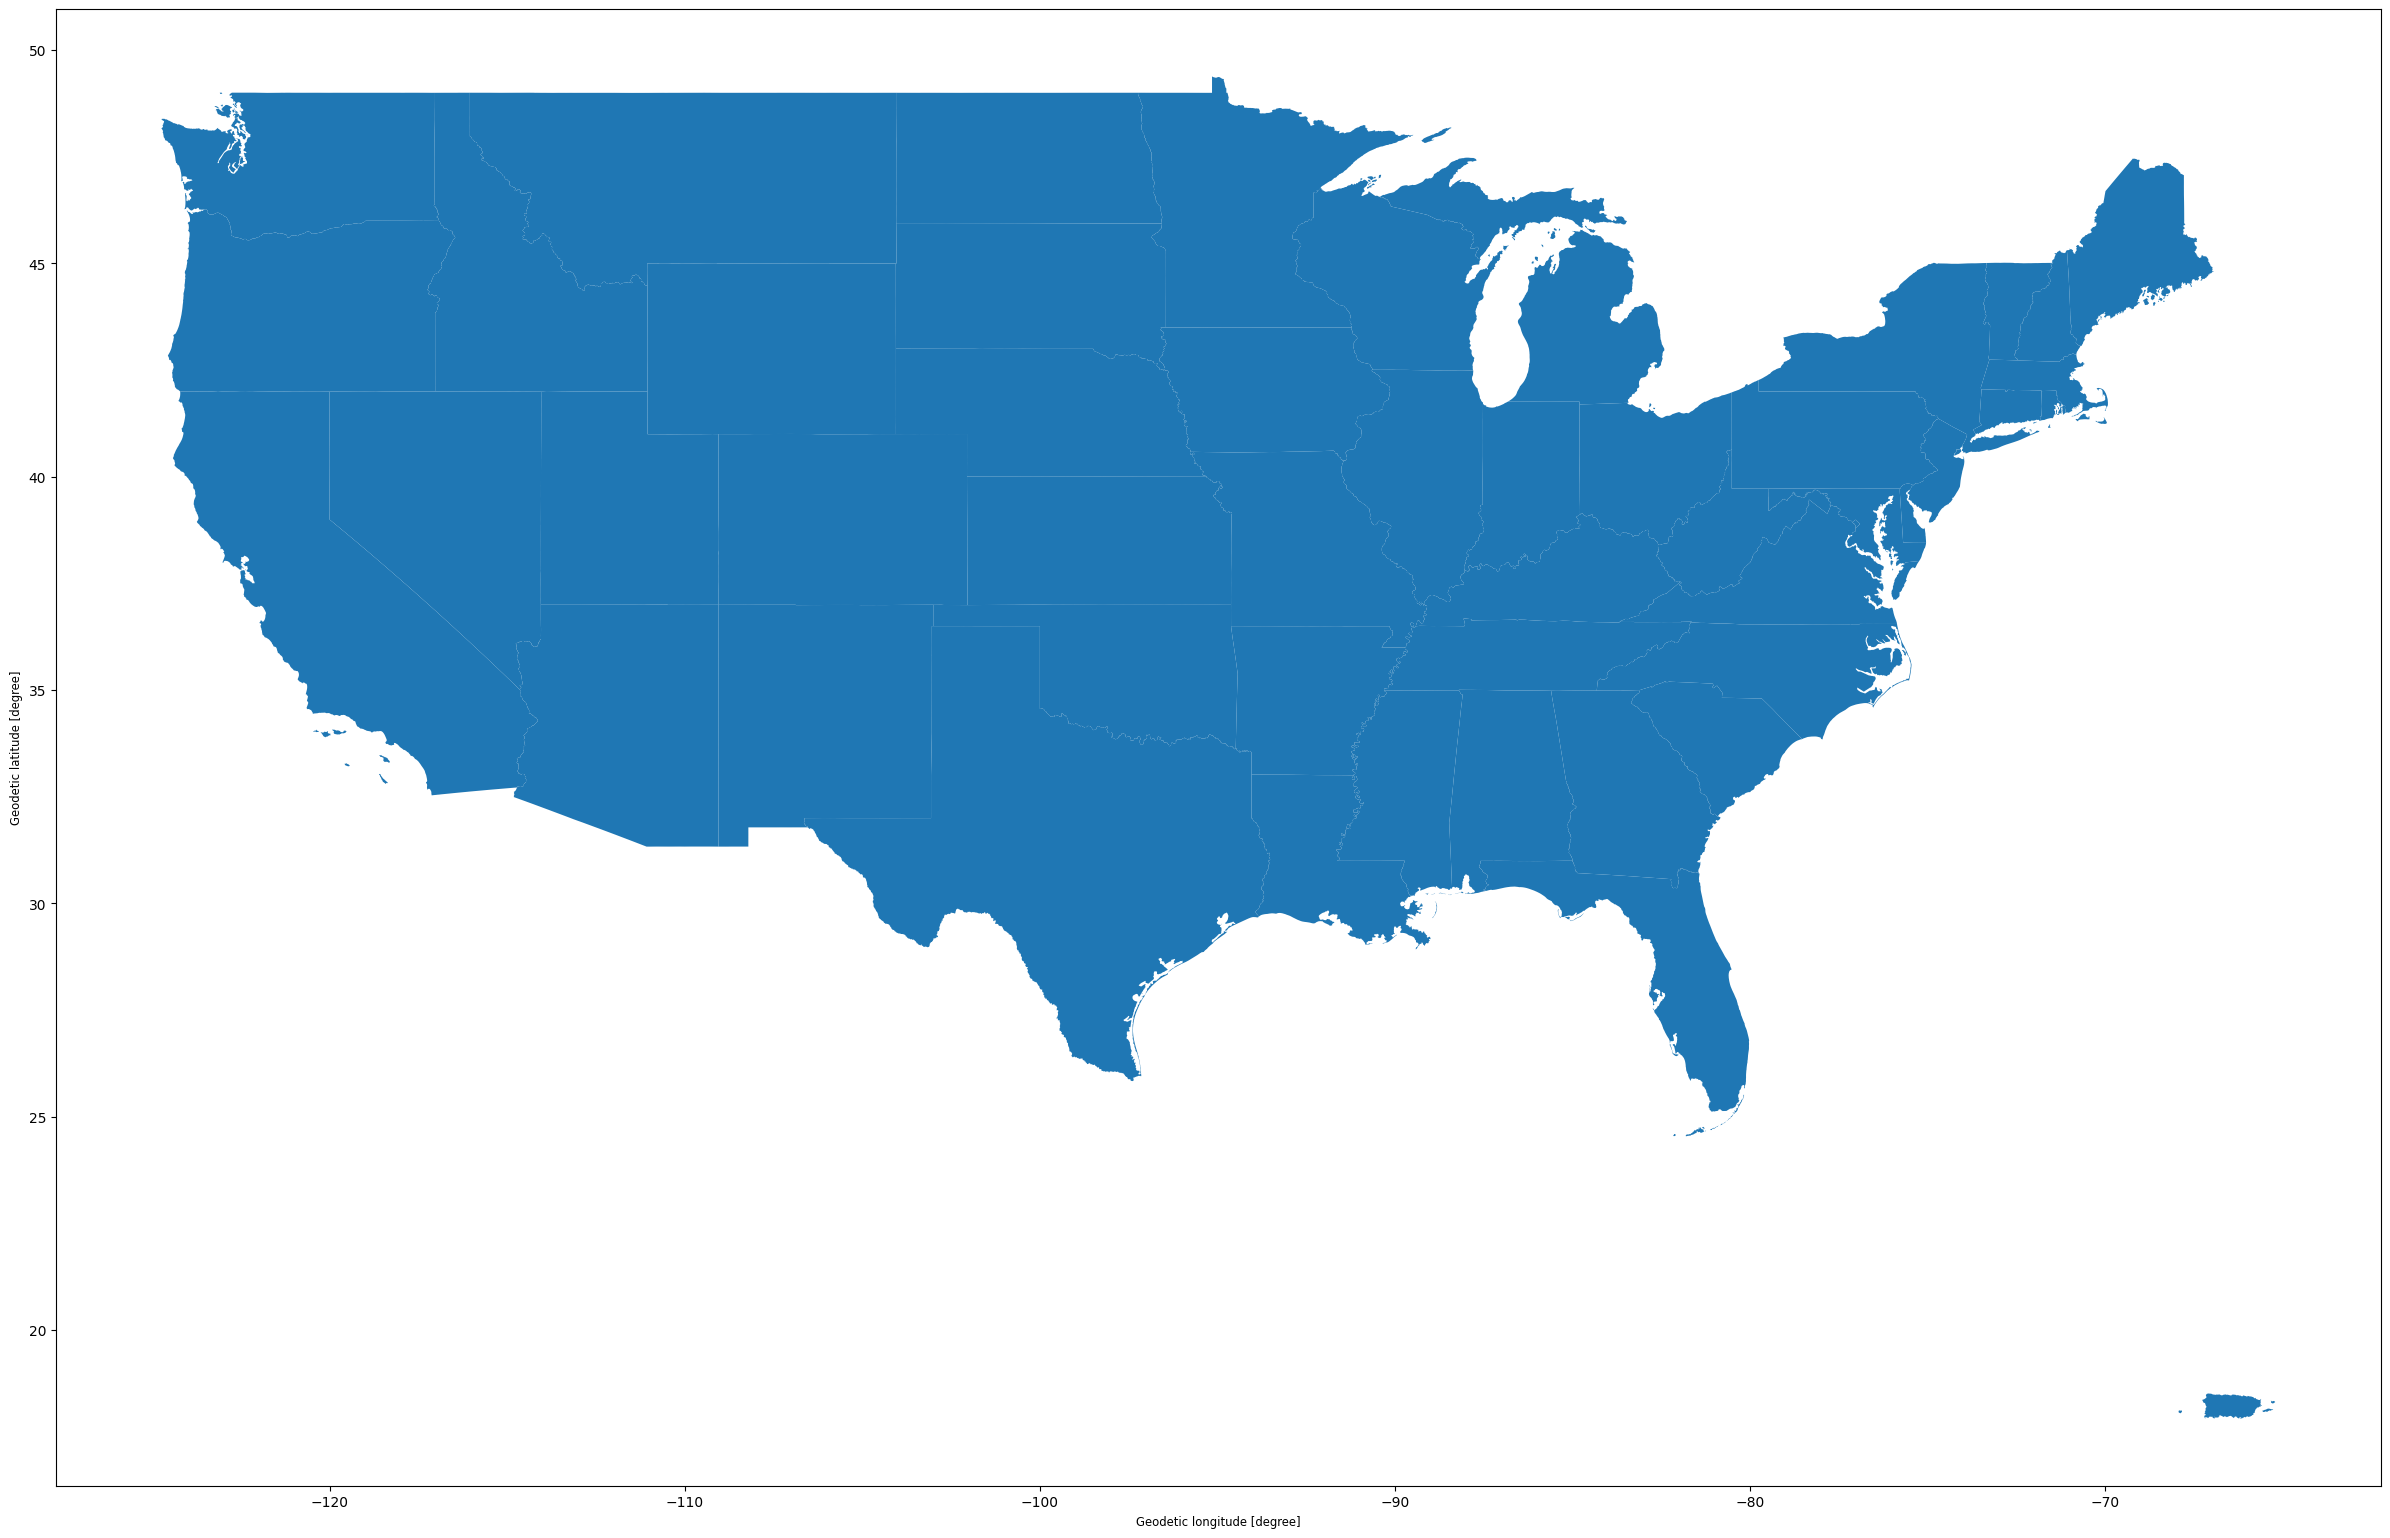

In [3]:
# Q4 : Plot the US states (Alaska and Hawaii excluded)
US = country[~country["NAME"].isin(["Alaska","Hawaii"])].plot(figsize=(30,20))

In [4]:
# Pre-supplied: read in the hurricane Florence data, drop the advisory bookkeeping columns,
# fix the longitude sign, and have a look at the dataframe.
# The Long column holds a positive "degrees west" magnitude, not a signed longitude -- a common
# quirk of NHC advisory data.

florence = pd.read_csv(track_path)
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
florence["Long"] = 0 - florence["Long"]
florence.head(3)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six


In [5]:
# Q5 : Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(
    florence,
    geometry = gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326"
)
track_path

'/root/.cache/mlees/florence.csv'

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

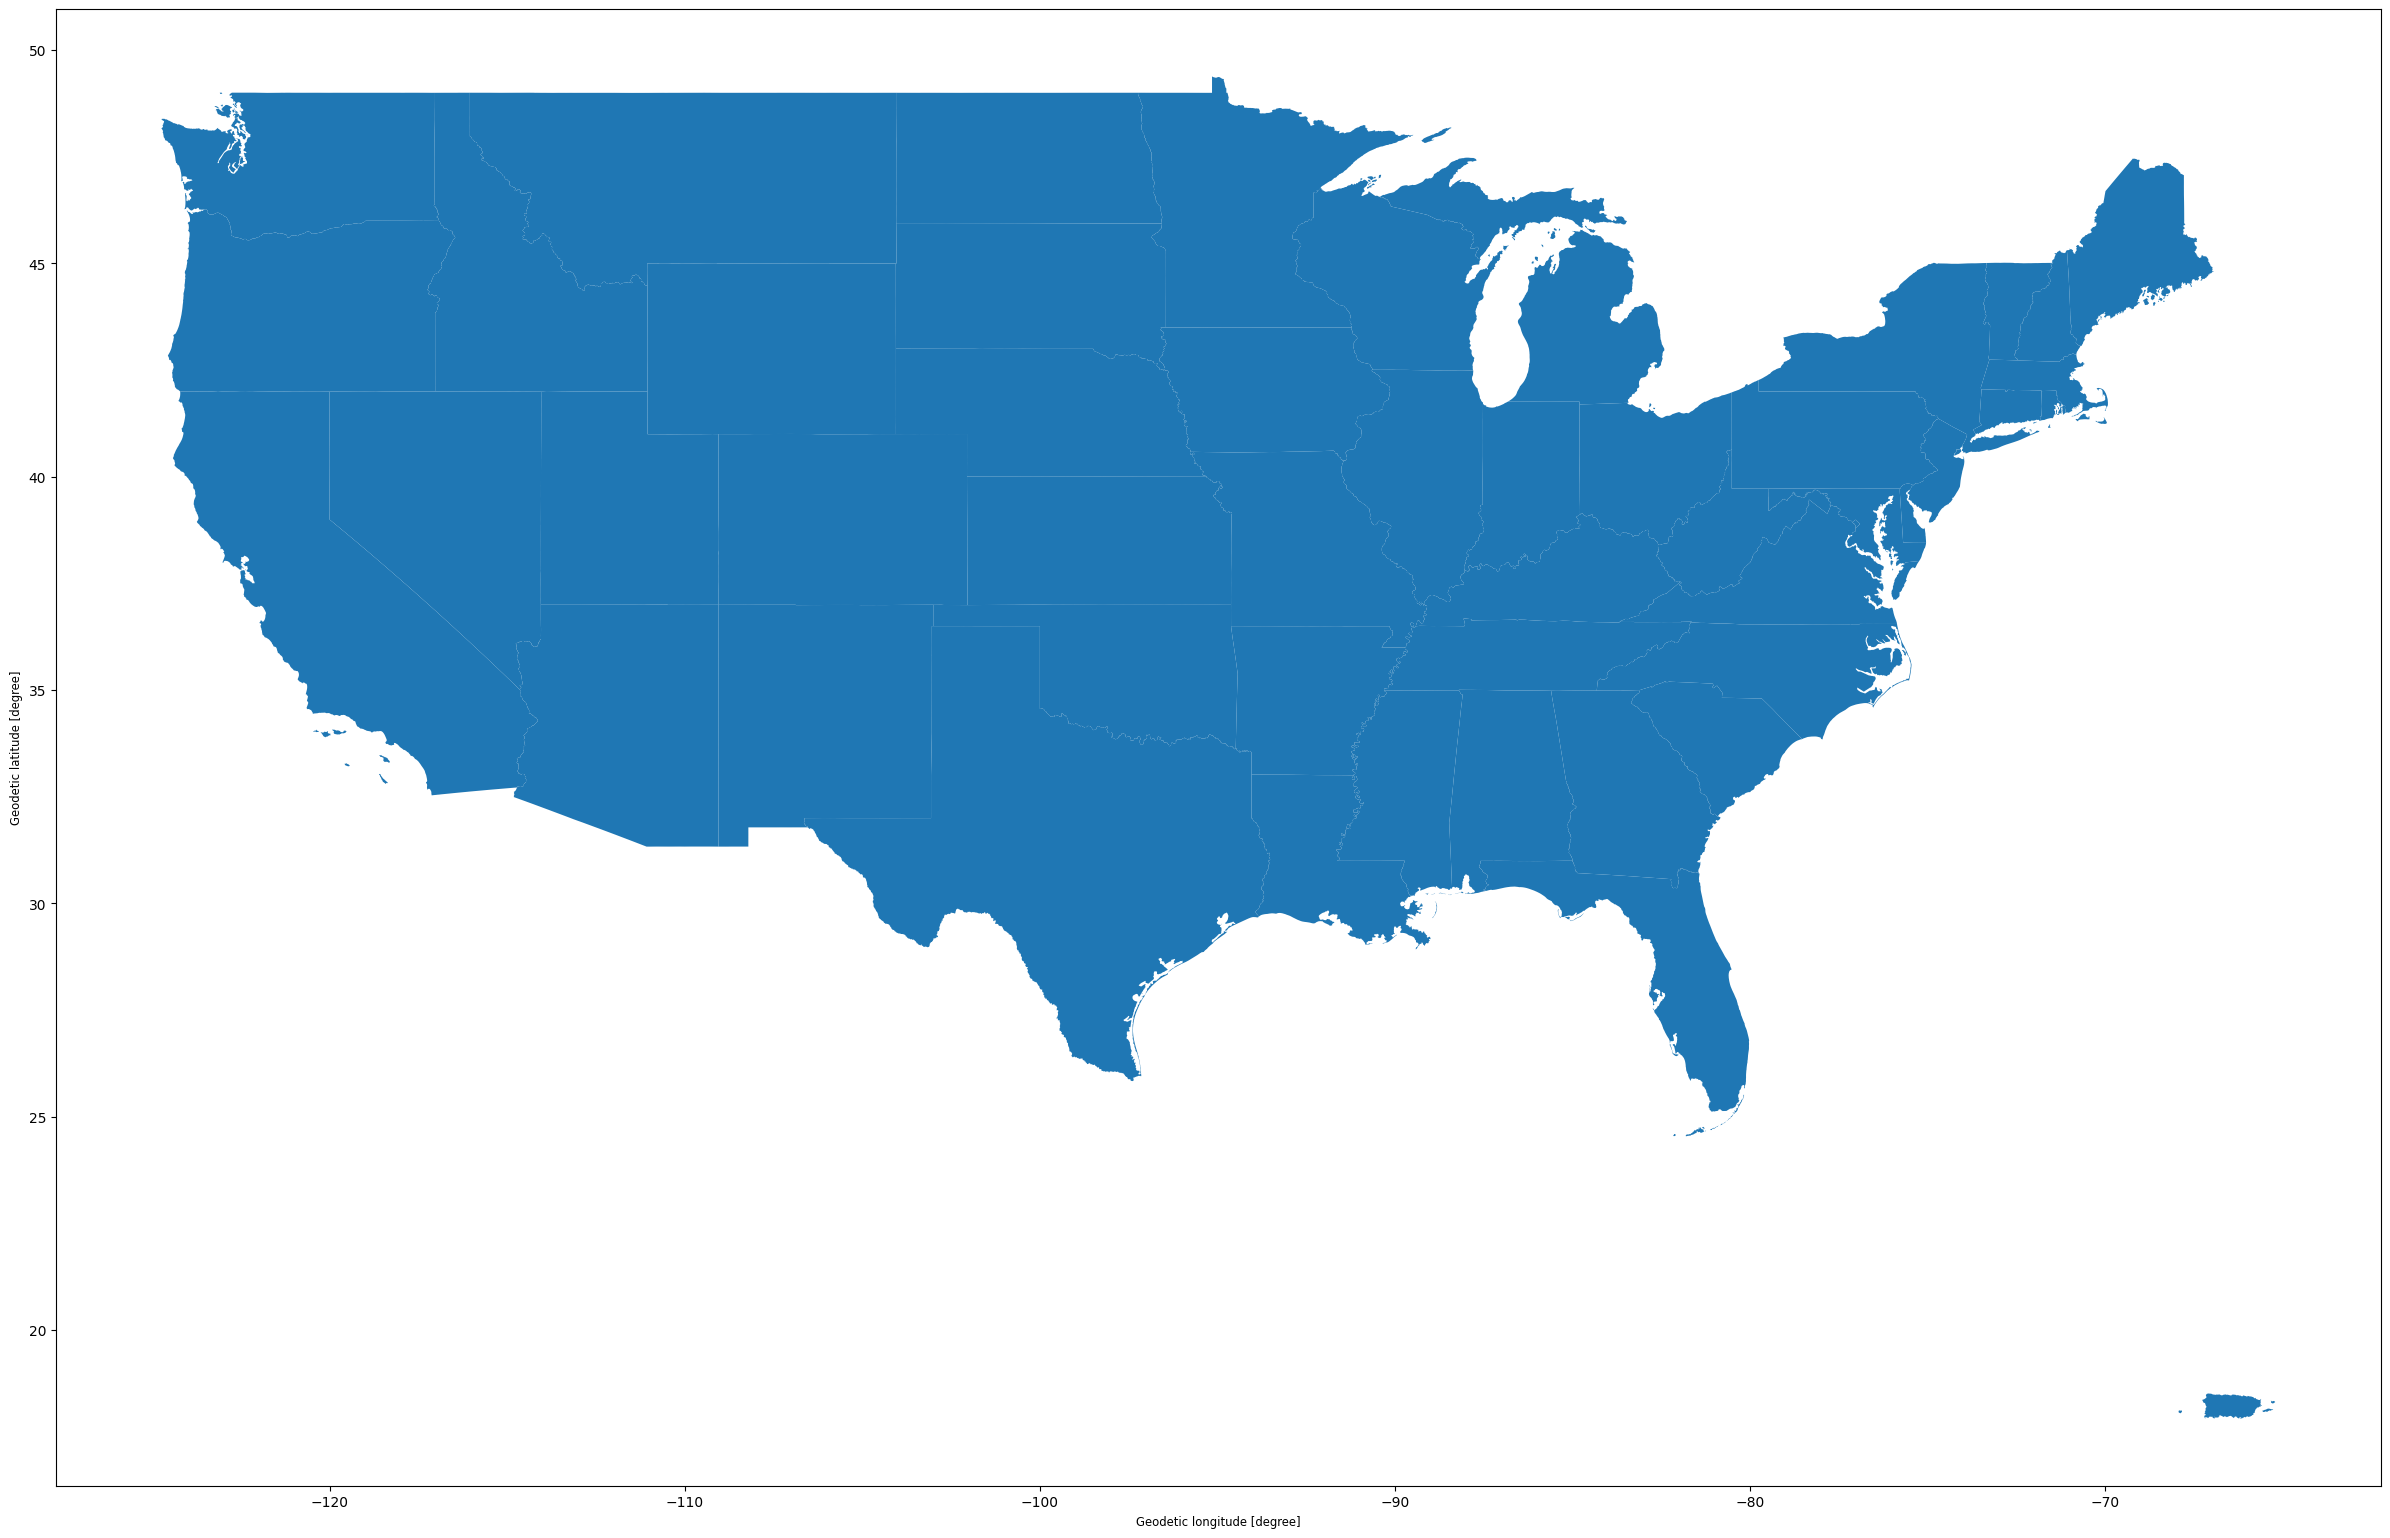

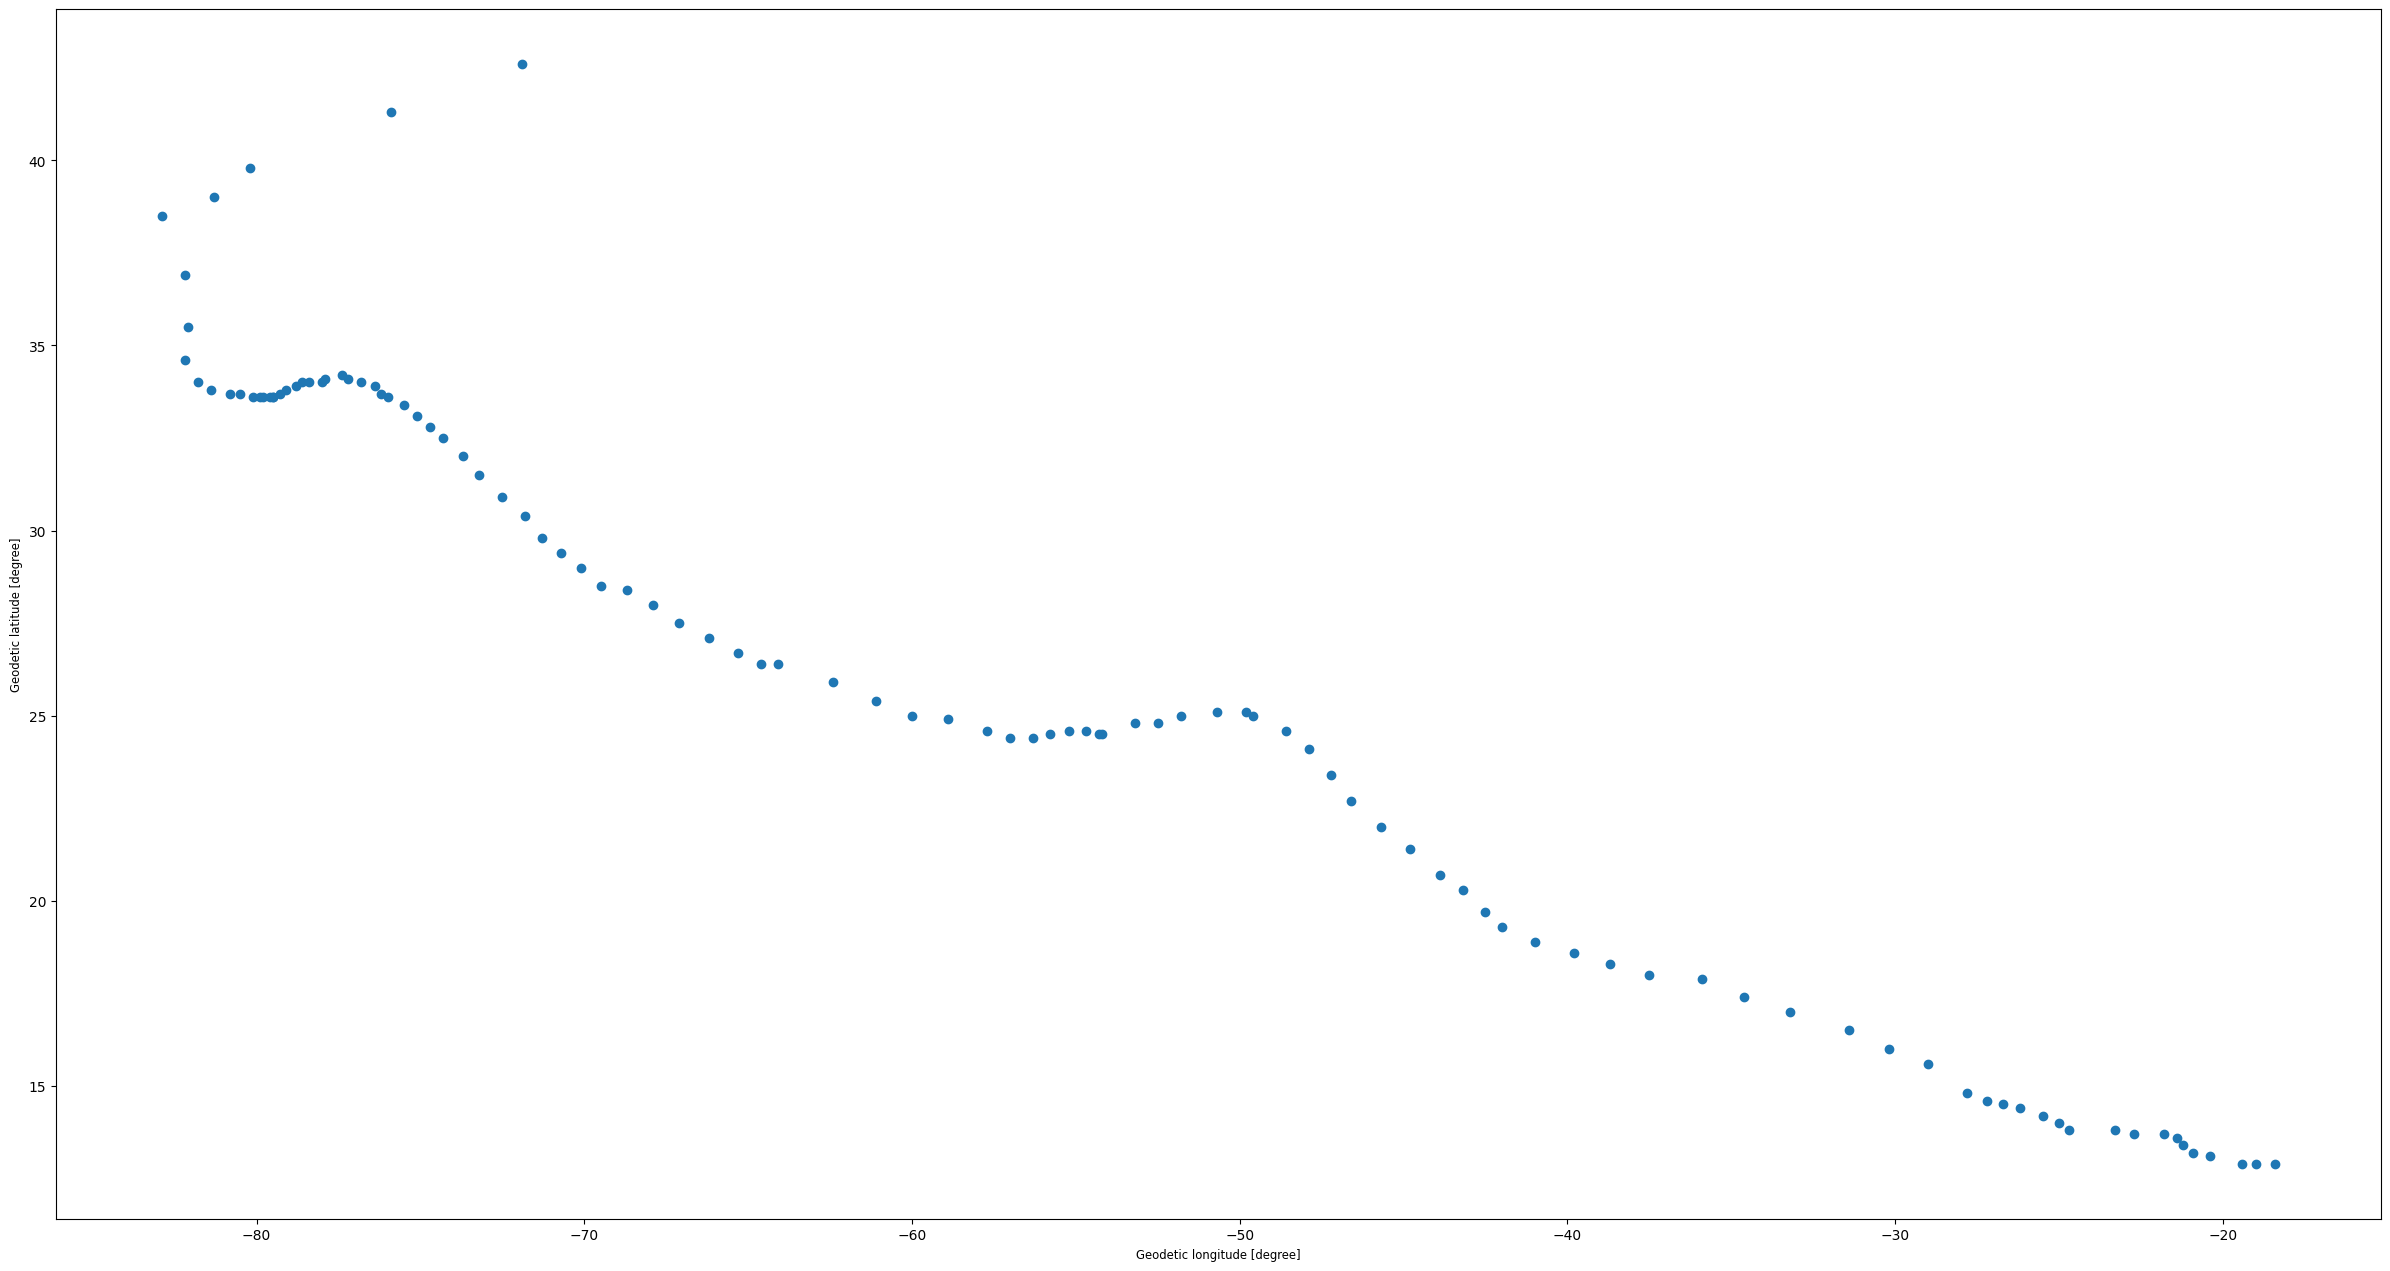

In [7]:
# Q6 : Plot to see the hurricane overlay the US map, with the hurricane position on top --> ERROR two graphs
US = country[~country["NAME"].isin(["Alaska","Hawaii"])].plot(figsize=(30,20))

gdf_florence.plot(figsize=(30,20))
